In [ ]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from tensorflow import keras
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.optimizers import Adam
from sklearn.metrics import confusion_matrix
from keras.layers import Dropout

#A.資料預處理

訓練資料形狀:(60000, 28, 28), 訓練答案形狀:(60000,)
測試資料形狀:(10000, 28, 28), 測試答案形狀:(10000,)


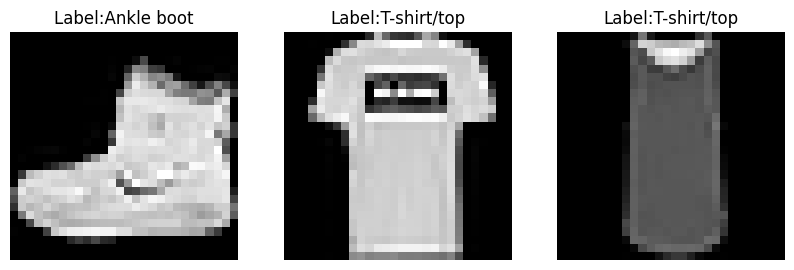

In [ ]:
(x_train,y_train),(x_test,y_test)=keras.datasets.fashion_mnist.load_data()
print(f"訓練資料形狀:{x_train.shape}, 訓練答案形狀:{y_train.shape}")
print(f"測試資料形狀:{x_test.shape}, 測試答案形狀:{y_test.shape}")
#正規化
x_Train= x_train.astype("float32") /255.0
x_Test= x_test.astype("float32") /255.0
x_Train = x_Train.reshape(-1, 784)
x_Test = x_Test.reshape(-1, 784)

#One-hot編碼
y_Train_onehot= keras.utils.to_categorical(y_train, 10)
y_Test_onehot= keras.utils.to_categorical(y_test, 10)

#訓練資料圖片、label名稱
label_names = ["T-shirt/top","Trouser","Pullover","Dress","Coat","Sandal","Shirt","Sneaker","Bag","Ankle boot"]
plt.figure(figsize=(10, 3))
for i in range(3):
    plt.subplot(1, 3, i+1)
    plt.imshow(x_train[i], cmap="gray")
    plt.title(f"Label:{label_names[y_train[i]]}")
    plt.axis("off")
plt.show()

#B.建立神經網路模型

In [ ]:
model = Sequential()
#隱藏層(1)
model.add(Dense(units=512,
        input_dim=784,
        kernel_initializer='normal',
        activation='relu'))
#防止過度擬合
model.add(Dropout(0.5))
print("第一層參數個數:784*1000+1000=785000\n")

#隱藏層(2)
model.add(Dense(units=258,
        kernel_initializer='normal',
        activation='relu'))
model.add(Dropout(0.5))
print("第二層參數個數:1000*500+500=500500\n")

#輸出層
model.add(Dense(units=10,
        kernel_initializer='normal',
        activation='softmax'))
print("輸出層參數個數:500*10+10=5010\n")

model.summary()

第一層參數個數:784*1000+1000=785000

第二層參數個數:1000*500+500=500500

輸出層參數個數:500*10+10=5010



/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_15 (Dense)                │ (None, 512)            │       401,920 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_10 (Dropout)            │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_16 (Dense)                │ (None, 258)            │       132,354 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_11 (Dropout)            │ (None, 258)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_17 (Dense)                │ (None, 10)             │         2,590 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 536,864 (2.05 MB)

 Trainable params: 536,864 (2.05 MB)

 Non-trainable params: 0 (0.00 B)

#C.訓練神經網路模型

In [ ]:
#輸入層
print("輸入層input shape: (None, 784)\n")
#第一層隱藏層
print("第一層隱藏層Output Shape: (None, 1000)\n")
#第一層Dropout層
print("第一層Dropout層Output Shape: (None, 1000)\n")
#第二層隱藏層
print("第二層隱藏層Output Shape: (None, 500)\n")
#第二層Dropout層
print("第二層Dropout層Output Shape: (None, 500)\n")
#輸出層
print("輸出層Output Shape: (None, 10)\n")
model.summary()
model.compile(loss='categorical_crossentropy',
        optimizer=Adam(learning_rate=0.0005), metrics=['accuracy'])

train_history =model.fit(x=x_Train,y=y_Train_onehot,validation_split=0.2,
            epochs=20, batch_size=140,verbose=2)

輸入層input shape: (None, 784)

第一層隱藏層Output Shape: (None, 1000)

第一層Dropout層Output Shape: (None, 1000)

第二層隱藏層Output Shape: (None, 500)

第二層Dropout層Output Shape: (None, 500)

輸出層Output Shape: (None, 10)



Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_15 (Dense)                │ (None, 512)            │       401,920 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_10 (Dropout)            │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_16 (Dense)                │ (None, 258)            │       132,354 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_11 (Dropout)            │ (None, 258)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_17 (Dense)                │ (None, 10)             │         2,590 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 536,864 (2.05 MB)

 Trainable params: 536,864 (2.05 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
343/343 - 7s - 22ms/step - accuracy: 0.7293 - loss: 0.7635 - val_accuracy: 0.8392 - val_loss: 0.4648
Epoch 2/20
343/343 - 6s - 19ms/step - accuracy: 0.8254 - loss: 0.4902 - val_accuracy: 0.8487 - val_loss: 0.4132
Epoch 3/20
343/343 - 6s - 18ms/step - accuracy: 0.8418 - loss: 0.4375 - val_accuracy: 0.8618 - val_loss: 0.3793
Epoch 4/20
343/343 - 5s - 15ms/step - accuracy: 0.8509 - loss: 0.4111 - val_accuracy: 0.8687 - val_loss: 0.3655
Epoch 5/20
343/343 - 7s - 19ms/step - accuracy: 0.8597 - loss: 0.3896 - val_accuracy: 0.8734 - val_loss: 0.3585
Epoch 6/20
343/343 - 5s - 15ms/step - accuracy: 0.8654 - loss: 0.3728 - val_accuracy: 0.8763 - val_loss: 0.3462
Epoch 7/20
343/343 - 7s - 20ms/step - accuracy: 0.8697 - loss: 0.3595 - val_accuracy: 0.8772 - val_loss: 0.3354
Epoch 8/20
343/343 - 5s - 15ms/step - accuracy: 0.8719 - loss: 0.3504 - val_accuracy: 0.8793 - val_loss: 0.3350
Epoch 9/20
343/343 - 6s - 18ms/step - accuracy: 0.8755 - loss: 0.3390 - val_accuracy: 0.8826 - val_loss:

#D.以折線圖顯示訓練過程

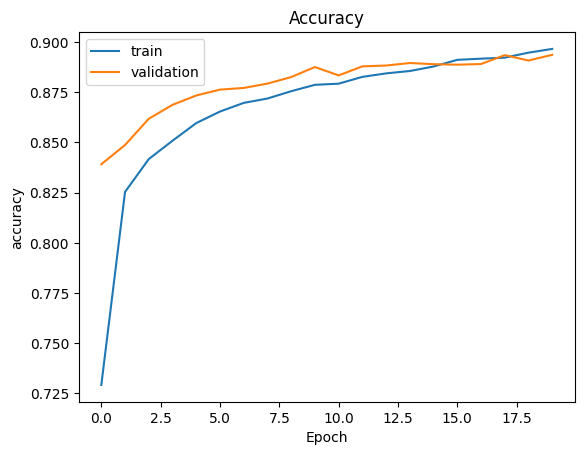

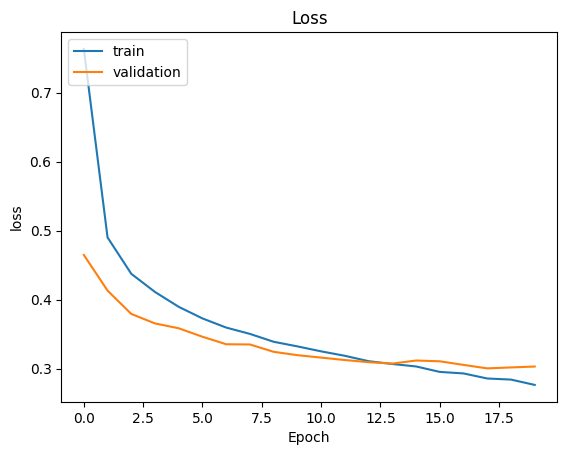

In [ ]:
def show_train_history(name,train_history,train,validation):
    plt.plot(train_history.history[train])
    plt.plot(train_history.history[validation])
    plt.title(name)
    plt.ylabel(train)
    plt.xlabel('Epoch')
    plt.legend(['train', 'validation'], loc='upper left')
    plt.show()
#準確率
show_train_history("Accuracy",train_history,'accuracy','val_accuracy')
#損失誤差
show_train_history("Loss",train_history,'loss','val_loss')

#E.評估模型準確率

In [ ]:
scores = model.evaluate(x_Test, y_Test_onehot)
print("\n")
print('accuracy=',scores[1])
print("老師我自首!!!我改了很多次數據,但我最高準確率也只能到0.897")

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8822 - loss: 0.3313


accuracy= 0.8822000026702881
老師我自首!!!我改了很多次數據,但我最高準確率也只能到0.897


#F.進行預測與呈現結果

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step


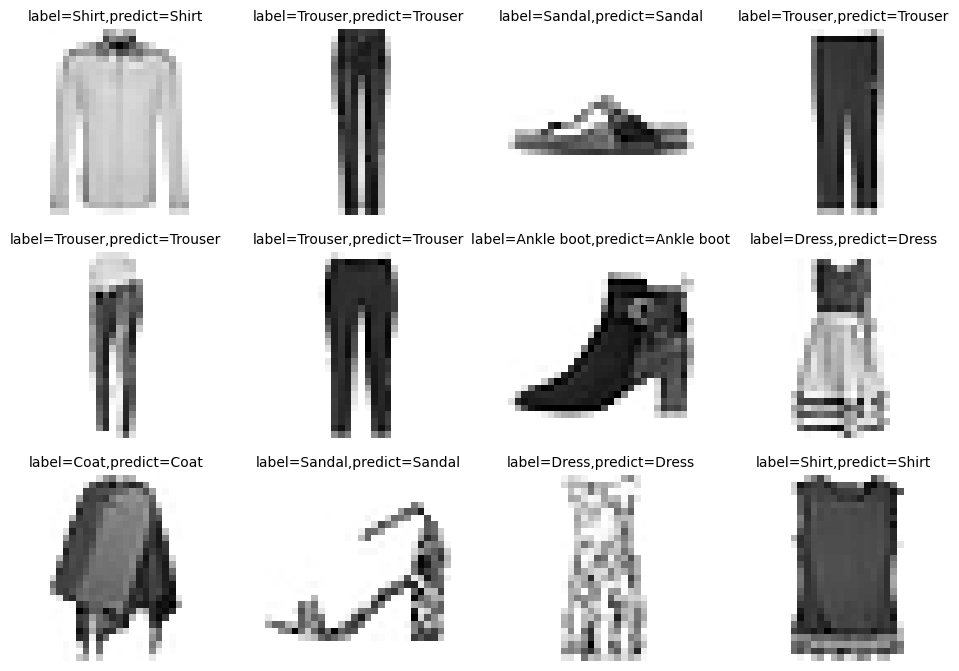

In [59]:
predictions_prob = model.predict(x_Test)
prediction = np.argmax(predictions_prob, axis=1)
def plot_images_labels_prediction(images,labels,prediction,idx,num=12): #顯示12張
  fig = plt.gcf()
  fig.set_size_inches(12, 14)
  for i in range(0, num):
    ax=plt.subplot(5,4, 1+i)  #5列4行,但我設定是12張所以不會到5列4行
    ax.imshow(images[idx], cmap='binary')
    title= "label=" +label_names[labels[idx]]
    if len(prediction)>0:
            title+=",predict="+label_names[prediction[idx]]

    ax.set_title(title, fontsize=10)
    plt.axis("off")
    idx += 1
  plt.show()
plot_images_labels_prediction(x_test, y_test,prediction,idx=550)#第501張開始

#G.混淆矩陣呈現預測結果

In [ ]:
import pandas as pd

y_test_names = [label_names[i] for i in y_test]
prediction_names = [label_names[i] for i in prediction]

pd.crosstab(y_test_names,prediction_names,
      rownames=['實際答案'],colnames=['模型預測'])

模型預測,Ankle boot,Bag,Coat,Dress,Pullover,Sandal,Shirt,Sneaker,T-shirt/top,Trouser
實際答案,,,,,,,,,,
Ankle boot,945,0,0,0,0,11,1,43,0,0
Bag,0,974,3,5,5,2,5,3,3,0
Coat,0,4,774,39,120,0,62,0,0,1
Dress,0,5,28,911,9,0,23,0,18,6
Pullover,0,3,80,13,818,0,73,0,13,0
Sandal,9,2,0,1,0,969,0,19,0,0
Shirt,0,15,61,30,87,0,653,0,153,1
Sneaker,22,0,0,0,0,23,0,955,0,0
T-shirt/top,0,13,3,29,18,0,82,0,855,0


#H.儲存完整模型

In [ ]:
model.save("hw3_fashion_mnist_dnn_model.h5")